# Behavioral Drift Analysis

Compare customer shopping behavior between consecutive months and calculate an initial drift score.


In [22]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Download the same dataset used in the EDA notebook
DATA_URL = (
    "https://raw.githubusercontent.com/"
    "Break-Through-Tech/"
    "Amazon-1A-discovering-customer-lifecycle-states-and-behavioral-drift-for-early-churn-detection/"
    "refs/heads/main/data/online_retail_II.csv"
)

DATA_PATH = Path("/content/online_retail_II.csv")

# Download only if the file is not already available
if not DATA_PATH.exists():
    import urllib.request
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

# Load the transaction data
raw = pd.read_csv(DATA_PATH, low_memory=False)

print("Loaded transactions:", len(raw))
print("Dataset shape:", raw.shape)

raw.head()


Loaded transactions: 541910
Dataset shape: (541910, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## Preparing customer transactions

In [23]:
required = {"Invoice", "StockCode", "Quantity", "Price", "Customer ID", "InvoiceDate"}
missing = required - set(raw.columns)
if missing:
    raise ValueError(f"Missing required CSV columns: {sorted(missing)}")

transactions = raw.dropna(subset=["Customer ID"]).copy()
transactions["InvoiceDate"] = pd.to_datetime(transactions["InvoiceDate"], errors="coerce")
for col in ["Quantity", "Price"]:
    transactions[col] = pd.to_numeric(transactions[col], errors="coerce")

before_validity = len(transactions)
transactions = transactions.dropna(subset=["InvoiceDate", "Quantity", "Price", "Invoice", "StockCode"])
print(f"Dropped {len(raw) - before_validity:,} rows without Customer ID")
print(f"Dropped {before_validity - len(transactions):,} rows with missing/invalid required values")

# Customer IDs are numeric in the original EDA. Match its string representation.
ids = pd.to_numeric(transactions["Customer ID"], errors="coerce")
if ids.isna().any() or (ids % 1 != 0).any():
    raise ValueError("Customer ID contains non-integer/non-numeric values; inspect before proceeding.")
transactions["Customer ID"] = ids.astype("int64").astype(str)
transactions["StockCode"] = transactions["StockCode"].astype(str)
transactions["Invoice"] = transactions["Invoice"].astype(str)
transactions["InvoiceDate"] = transactions["InvoiceDate"].dt.normalize()
transactions = transactions.drop_duplicates().copy()

transactions["SnapshotMonth"] = transactions["InvoiceDate"].dt.to_period("M")
transactions["Revenue"] = transactions["Quantity"] * transactions["Price"]
transactions["IsCancellation"] = transactions["Invoice"].str.startswith("C")
print(f"Transactions after preprocessing: {len(transactions):,}")

Dropped 135,080 rows without Customer ID
Dropped 0 rows with missing/invalid required values
Transactions after preprocessing: 401,604


## Monthly customer features

In [24]:
# Preserve the EDA's customer/product/month netting approach.
netted = (
    transactions.groupby(["Customer ID", "StockCode", "SnapshotMonth"], as_index=False)
    .agg(
        Quantity=("Quantity", "sum"),
        Invoice=("Invoice", "first"),
        Revenue=("Revenue", "sum"),
        CancelCount=("IsCancellation", "sum"),
    )
)
monthly_data = (
    netted.groupby(["Customer ID", "SnapshotMonth"], as_index=False)
    .agg(
        month_orders=("Invoice", "nunique"),
        month_revenue=("Revenue", "sum"),
        month_quantity=("Quantity", "sum"),
        month_diff_items=("StockCode", "nunique"),
        month_cancellations=("CancelCount", "sum"),
    )
)

# Include every month from the first observed transaction to the dataset end,
# including months without purchases. Do not filter by churn label here.
first_month = transactions.groupby("Customer ID")["SnapshotMonth"].min()
last_month = transactions["SnapshotMonth"].max()
calendar = pd.concat(
    [pd.DataFrame({"Customer ID": customer_id,
                   "SnapshotMonth": pd.period_range(start=first, end=last_month, freq="M")})
     for customer_id, first in first_month.items()],
    ignore_index=True,
)
monthly = calendar.merge(monthly_data, on=["Customer ID", "SnapshotMonth"], how="left", validate="one_to_one")
count_cols = ["month_orders", "month_revenue", "month_quantity", "month_diff_items", "month_cancellations"]
monthly[count_cols] = monthly[count_cols].fillna(0)
monthly = monthly.sort_values(["Customer ID", "SnapshotMonth"]).reset_index(drop=True)
print(f"Customer-month observations: {len(monthly):,}; customers: {monthly['Customer ID'].nunique():,}")

Customer-month observations: 37,436; customers: 4,372


## Recency and average order value

In [25]:

# One row per positive-quantity invoice; this matches EDA's recency basis.
orders = (
    transactions.loc[
        transactions["Quantity"] > 0,
        ["Customer ID", "Invoice", "InvoiceDate"]
    ]
    .groupby(["Customer ID", "Invoice"], as_index=False)["InvoiceDate"]
    .min()
    .rename(columns={"InvoiceDate": "last_order"})
    .sort_values("last_order")
)

if orders.empty:
    raise ValueError("No positive-quantity invoices; recency cannot be calculated.")

# Use the complete last day of each month.
monthly["snapshot_end"] = monthly["SnapshotMonth"].dt.to_timestamp(how="end")

monthly = pd.merge_asof(
    monthly.sort_values("snapshot_end"),
    orders[["Customer ID", "last_order"]].sort_values("last_order"),
    left_on="snapshot_end",
    right_on="last_order",
    by="Customer ID",
    direction="backward",
    allow_exact_matches=True,
)

monthly["recency_days"] = (
    monthly["snapshot_end"] - monthly["last_order"]
).dt.days

monthly["avg_order_value"] = (
    monthly["month_revenue"]
    / monthly["month_orders"].replace(0, np.nan)
).fillna(0)

monthly = monthly.sort_values(
    ["Customer ID", "SnapshotMonth"]
).reset_index(drop=True)

display(monthly.head())


,Customer ID,SnapshotMonth,month_orders,month_revenue,month_quantity,month_diff_items,month_cancellations,snapshot_end,last_order,recency_days,avg_order_value
0,12346,2011-01,1.0,0.0,0.0,1.0,1.0,2011-01-31 23:59:59.999999999,2011-01-18,13.0,0.0
1,12346,2011-02,0.0,0.0,0.0,0.0,0.0,2011-02-28 23:59:59.999999999,2011-01-18,41.0,0.0
2,12346,2011-03,0.0,0.0,0.0,0.0,0.0,2011-03-31 23:59:59.999999999,2011-01-18,72.0,0.0
3,12346,2011-04,0.0,0.0,0.0,0.0,0.0,2011-04-30 23:59:59.999999999,2011-01-18,102.0,0.0
4,12346,2011-05,0.0,0.0,0.0,0.0,0.0,2011-05-31 23:59:59.999999999,2011-01-18,133.0,0.0


## Month-over-month changes

In [26]:
drift_features = monthly.copy()
measures = ["month_orders", "month_revenue", "month_diff_items", "avg_order_value", "recency_days"]
groups = drift_features.groupby("Customer ID", sort=False)

for name in measures:
    drift_features[f"prev_{name}"] = groups[name].shift(1)
    drift_features[f"change_{name}"] = drift_features[name] - drift_features[f"prev_{name}"]

for name in ["month_orders", "month_revenue", "month_diff_items", "avg_order_value"]:
    previous = drift_features[f"prev_{name}"]
    drift_features[f"pct_change_{name}"] = (
        100 * drift_features[f"change_{name}"] / previous.where(previous > 0)
    )

# Explicitly verify that every available predecessor is the prior CALENDAR month.
previous_month = groups["SnapshotMonth"].shift(1)
valid_previous_month = previous_month.isna() | (
    drift_features["SnapshotMonth"] == (previous_month + 1)
)
assert valid_previous_month.all(), "Nonconsecutive customer-month rows found"

has_previous = previous_month.notna()
# Recency must exist in both months to score all five components.
has_recency_pair = drift_features["recency_days"].notna() & drift_features["prev_recency_days"].notna()

warning_columns = {
    "orders_declined": drift_features["change_month_orders"] < 0,
    "revenue_declined": drift_features["change_month_revenue"] < 0,
    "unique_items_declined": drift_features["change_month_diff_items"] < 0,
    "aov_declined": drift_features["change_avg_order_value"] < 0,
    "recency_increased": drift_features["change_recency_days"] > 0,
}
for column, condition in warning_columns.items():
    drift_features[column] = condition.where(has_previous & has_recency_pair).astype("boolean")

score_columns = list(warning_columns)
drift_features["drift_score"] = drift_features[score_columns].sum(axis=1, min_count=5).astype("Int64")
drift_features["drift_level"] = pd.cut(
    drift_features["drift_score"].astype("float"),
    bins=[-0.5, 1.5, 3.5, 5.5], labels=["Low", "Moderate", "High"],
)
print("Scored customer-months:", drift_features["drift_score"].notna().sum())
print(drift_features["drift_level"].value_counts(dropna=False))

Scored customer-months: 32468
drift_level
Low         21360
High         9046
NaN          4968
Moderate     2062
Name: count, dtype: int64


## Results

All validation checks passed!


,Customer ID,SnapshotMonth,month_orders,month_revenue,month_diff_items,avg_order_value,recency_days,change_month_orders,change_month_revenue,change_month_diff_items,change_avg_order_value,change_recency_days,drift_score,drift_level
0,12346,2011-01,1.0,0.00,1.0,0.00,13.0,NaN,NaN,NaN,NaN,NaN,<NA>,NaN
1,12346,2011-02,0.0,0.00,0.0,0.00,41.0,-1.0,0.00,-1.0,0.00,28.0,3,Moderate
2,12346,2011-03,0.0,0.00,0.0,0.00,72.0,0.0,0.00,0.0,0.00,31.0,1,Low
3,12346,2011-04,0.0,0.00,0.0,0.00,102.0,0.0,0.00,0.0,0.00,30.0,1,Low
4,12346,2011-05,0.0,0.00,0.0,0.00,133.0,0.0,0.00,0.0,0.00,31.0,1,Low
5,12346,2011-06,0.0,0.00,0.0,0.00,163.0,0.0,0.00,0.0,0.00,30.0,1,Low
6,12346,2011-07,0.0,0.00,0.0,0.00,194.0,0.0,0.00,0.0,0.00,31.0,1,Low
7,12346,2011-08,0.0,0.00,0.0,0.00,225.0,0.0,0.00,0.0,0.00,31.0,1,Low
8,12346,2011-09,0.0,0.00,0.0,0.00,255.0,0.0,0.00,0.0,0.00,30.0,1,Low
9,12346,2011-10,0.0,0.00,0.0,0.00,286.0,0.0,0.00,0.0,0.00,31.0,1,Low


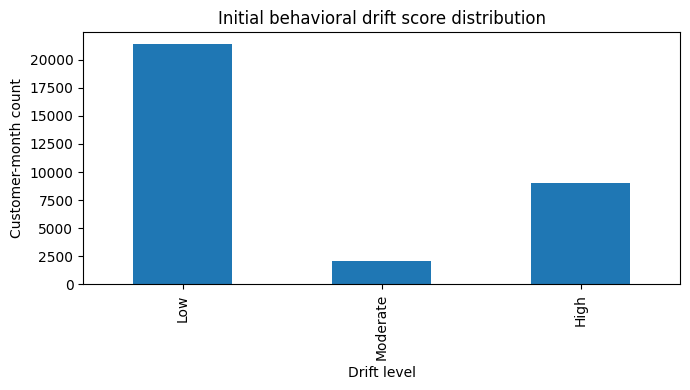

In [27]:

# Validate the behavioral drift features
assert not drift_features.duplicated(
    ["Customer ID", "SnapshotMonth"]
).any()

assert drift_features["drift_score"].dropna().between(0, 5).all()

assert drift_features.loc[
    ~has_previous, "drift_score"
].isna().all()

# Missing last_order values are valid for months without prior purchases.
valid_dates = (
    drift_features["last_order"].isna()
    | (
        drift_features["snapshot_end"]
        >= drift_features["last_order"]
    )
)

assert valid_dates.all(), "Found purchases after the snapshot date"

print("All validation checks passed!")

show_cols = [
    "Customer ID",
    "SnapshotMonth",
    "month_orders",
    "month_revenue",
    "month_diff_items",
    "avg_order_value",
    "recency_days",
    "change_month_orders",
    "change_month_revenue",
    "change_month_diff_items",
    "change_avg_order_value",
    "change_recency_days",
    "drift_score",
    "drift_level",
]

display(drift_features[show_cols].head(20))

counts = (
    drift_features["drift_level"]
    .value_counts()
    .reindex(["Low", "Moderate", "High"], fill_value=0)
)

ax = counts.plot.bar(
    figsize=(7, 4),
    title="Initial behavioral drift score distribution"
)

ax.set(
    xlabel="Drift level",
    ylabel="Customer-month count"
)

plt.tight_layout()
plt.show()


## Exporting features

In [28]:
# Optional: export the new features separately from the original feat.csv.
# Keep this False until the results have been reviewed.
EXPORT_CSV = False
OUTPUT_PATH = Path('behavioral_drift_features.csv')

if EXPORT_CSV:
    if OUTPUT_PATH.exists():
        raise FileExistsError(f'File already exists: {OUTPUT_PATH}')
    drift_features.to_csv(OUTPUT_PATH, index=False)
    print('Saved:', OUTPUT_PATH)
